<a href="https://colab.research.google.com/github/sociallyH03ly/Overseas-Filipino-Workers-2025-Analysis/blob/main/2025_OFW_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup and loading

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_PATH = "SURVEY OF OFW 2025.csv"   # change if your file name differs
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded: {raw.shape[0]} rows, {raw.shape[1]} columns")

Loaded: 4215 rows, 45 columns


## 1. Cleaning and dictionary-based labels

In [ ]:
df = raw.replace(r"^\s*$", np.nan, regex=True)       # whitespace-only -> real NaN

num_cols = ["RREG","RQ3_SEX","RQ4_AGE","RQ5_TMSLEFT","RQ7_MSTAT","RQ8_HGRADE","RQ9_2DGT","RQ10_REASON",
            "RQ11_BASE","RQ12_CTRY","RQ13_RETURN","RQ14_INDWORK","RQ15_2DGT","RQ16_2DGT","RQ17_AVEMINC",
            "RQ19_NOMONTH","RQ20_RET","RQ22_REASON","RQ24_CASHREM","RQ25_CASHAMT","RQ26_MODE",
            "RQ271P_CONSUM","RQ272P_INVEST","RQ273P_SAVINGS","RQ274P_GIFT","RQ275P_OTHERS",
            "RQ28_RET6MOS","RQ29_CASHHOME","RQ30_INKIND","RQ31_KINDAMT","RURB2020","RSWGT"]
for c in num_cols: df[c] = pd.to_numeric(df[c], errors="coerce")

REGION = {13:"NCR",14:"CAR",1:"I Ilocos",2:"II Cagayan Valley",3:"III Central Luzon",4:"IV-A CALABARZON",
          17:"MIMAROPA",5:"V Bicol",6:"VI Western Visayas",18:"NIR",7:"VII Central Visayas",
          8:"VIII Eastern Visayas",9:"IX Zamboanga",10:"X Northern Mindanao",11:"XI Davao",
          12:"XII SOCCSKSARGEN",16:"XIII Caraga",19:"ARMM"}
MARITAL = {1:"Single",2:"Married",3:"Common-law/Live-in",4:"Widowed",5:"Divorced",6:"Separated",7:"Annulled",8:"Not reported"}
COUNTRY = {100:"Africa",211:"Hong Kong",212:"Japan",213:"Taiwan",214:"Other East Asia",221:"Malaysia",
           222:"Singapore",223:"Other SE/S Asia",231:"Kuwait",232:"Qatar",233:"Saudi Arabia",234:"UAE",
           235:"Other W. Asia",300:"Australia",400:"Europe",500:"Americas",600:"Other"}
EDU = {0:"None",1:"Elementary",2:"Elementary",3:"High school",4:"High school",5:"High school",6:"High school",
       7:"Vocational/Post-secondary",8:"Vocational/Post-secondary",9:"College undergrad",10:"College grad",11:"Postgrad"}
RET_REASON = {1:"Visit friends/relatives",2:"End of contract",3:"COVID-19 repatriation",4:"Others"}
MODE = {1:"Bank",2:"Agency/local office",3:"Friends/co-workers",4:"Door-to-door",5:"Money transfer service",6:"Others"}

def occ_group(v):
    if pd.isna(v): return np.nan
    v = int(v)
    for lo, hi, name in [(11,14,"Managers"),(21,26,"Professionals"),(31,35,"Technicians"),(41,44,"Clerical support"),
                         (51,54,"Service and sales"),(61,63,"Skilled agri/fishery"),(71,75,"Craft and trades"),
                         (81,83,"Plant and machine operators"),(91,96,"Elementary"),(1,3,"Armed forces")]:
        if lo <= v <= hi: return name
    return "Non-gainful" if v == 9 else "Other"

df["Region"]    = df.RREG.map(REGION)
df["Sex"]       = df.RQ3_SEX.map({1:"Male",2:"Female"})
df["Marital"]   = df.RQ7_MSTAT.map(MARITAL)
df["Education"] = df.RQ8_HGRADE.map(EDU)
df["Urban"]     = df.RURB2020.map({1:"Urban",2:"Rural"})
df["Base"]      = df.RQ11_BASE.map({1:"Land-based",2:"Sea-based",3:"Other"})
df["Dest"]      = df.RQ12_CTRY.map(COUNTRY)
df["Occ_usual"] = df.RQ9_2DGT.map(occ_group)     # occupation BEFORE leaving (usual occupation)
df["Occ_abroad"]= df.RQ15_2DGT.map(occ_group)    # occupation ABROAD (use this for OFW work analysis)
df["Age_grp"]   = pd.cut(df.RQ4_AGE, [-1,24,34,44,54,200], labels=["<=24","25-34","35-44","45-54","55+"])
df["Returned"]  = df.RQ20_RET.eq(1)
df["Ret_reason"]= df.RQ22_REASON.map(RET_REASON)
df["Mode"]      = df.RQ26_MODE.map(MODE)
df["Remits"]    = df.RQ24_CASHREM.eq(1)
df["Worked"]    = df.RQ17_AVEMINC.notna()
df["Has_mix"]   = df[["RQ271P_CONSUM","RQ272P_INVEST","RQ273P_SAVINGS","RQ274P_GIFT","RQ275P_OTHERS"]].notna().all(axis=1)

miss = df.isna().sum(); display(miss[miss > 0].to_frame("Missing"))
print("Most missing values are skip patterns (e.g. no income if no work abroad), not errors.")

,Missing
RQ7_MSTAT,9
RQ8_HGRADE,9
RQ11_BASE,863
RQ15_2DGT,851
RQ16_2DGT,851
RQ17_AVEMINC,851
RQ19_NOMONTH,851
RQ21M_DTRET,2634
RQ21Y_DTRET,2634
RQ22_REASON,2634


Most missing values are skip patterns (e.g. no income if no work abroad), not errors.


In [ ]:
# Weighted helpers
def wmean(x, w):
    m = x.notna(); return np.average(x[m], weights=w[m]) if m.any() else np.nan
def wmedian(x, w):
    m = x.notna(); x, w = x[m].values, w[m].values
    if len(x) == 0: return np.nan
    o = np.argsort(x); x, w = x[o], w[o]; return x[np.searchsorted(np.cumsum(w)/w.sum(), 0.5)]
def wshare(df_, col):
    t = df_.groupby(col, observed=True).RSWGT.sum(); return (100*t/t.sum()).round(1).sort_values(ascending=False)
print(f"Weighted population: {df.RSWGT.sum():,.0f}")

Weighted population: 3,032,420


## 2. Descriptive analysis: unweighted sample vs weighted population

In [ ]:
cmp = pd.DataFrame({"Sample n": df.Sex.value_counts(),
                    "Sample %": (100*df.Sex.value_counts(normalize=True)).round(1),
                    "Weighted %": wshare(df, "Sex")})
display(cmp)
print(df.RQ4_AGE.describe().round(1).to_string())
print("Records with age < 15:", (df.RQ4_AGE < 15).sum(), "(check for data-entry issues)")

,Sample n,Sample %,Weighted %
Sex,,,
Female,2514,59.6,59.1
Male,1701,40.4,40.9


count    4215.0
mean       40.0
std        12.3
min         1.0
25%        31.0
50%        38.0
75%        47.0
max        92.0
Records with age < 15: 53 (check for data-entry issues)


In [ ]:
reg = pd.DataFrame({"Sample n": df.Region.value_counts(), "Sample %": (100*df.Region.value_counts(normalize=True)).round(1),
                    "Weighted %": wshare(df, "Region")}).sort_values("Weighted %", ascending=False)
display(reg)
print("Note: NCR leads the sample, but CALABARZON leads the weighted population. Use weights for population statements.")

,Sample n,Sample %,Weighted %
Region,,,
IV-A CALABARZON,300,7.1,21.0
NCR,780,18.5,17.1
III Central Luzon,374,8.9,10.0
I Ilocos,244,5.8,7.4
VI Western Visayas,263,6.2,6.5
VII Central Visayas,176,4.2,5.2
II Cagayan Valley,261,6.2,5.1
X Northern Mindanao,257,6.1,4.3
XII SOCCSKSARGEN,185,4.4,3.7


Note: NCR leads the sample, but CALABARZON leads the weighted population. Use weights for population statements.


Sex,Female,Male
Region,,
ARMM,41792,8448
CAR,31579,12270
I Ilocos,142224,81180
II Cagayan Valley,101919,53404
III Central Luzon,161215,142295
IV-A CALABARZON,369723,268258
IX Zamboanga,34921,19441
MIMAROPA,29324,21840
NCR,287659,230187


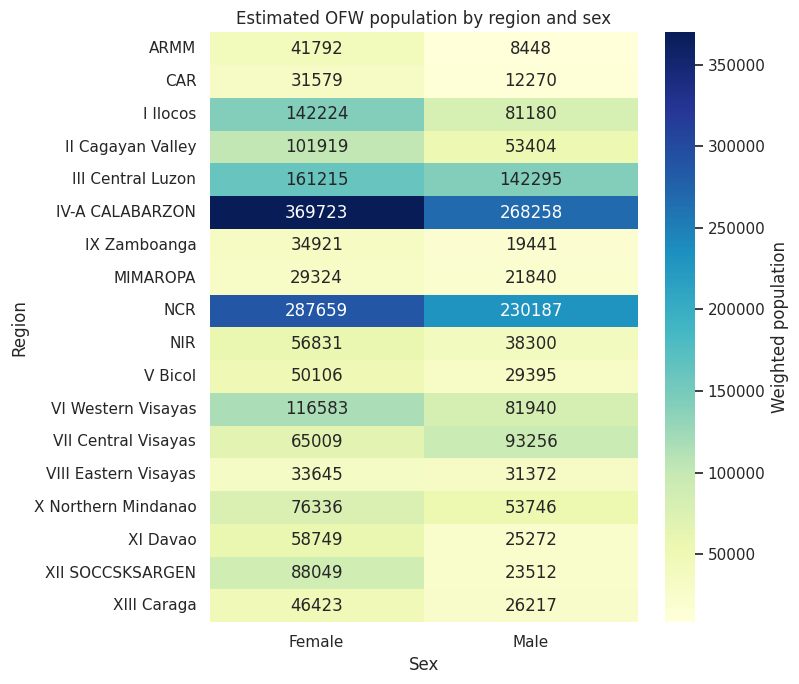

In [ ]:
region_sex = pd.crosstab(df.Region, df.Sex, values=df.RSWGT, aggfunc="sum").round(0).astype(int)
display(region_sex)
plt.figure(figsize=(8,7)); sns.heatmap(region_sex, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label":"Weighted population"})
plt.title("Estimated OFW population by region and sex"); plt.tight_layout(); plt.show()

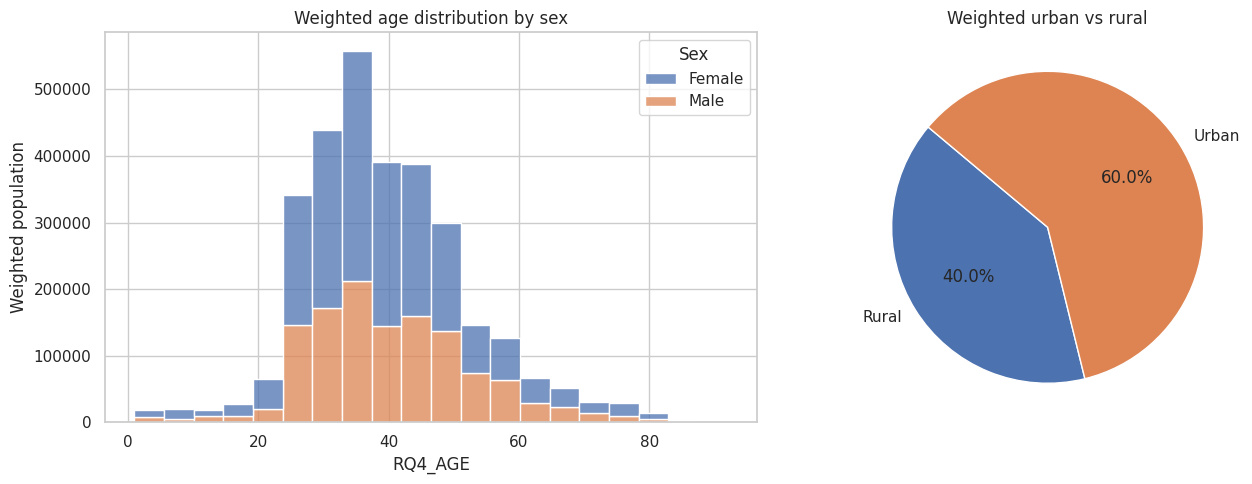

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(data=df, x="RQ4_AGE", hue="Sex", weights="RSWGT", multiple="stack", bins=20, ax=ax[0])
ax[0].set_title("Weighted age distribution by sex"); ax[0].set_ylabel("Weighted population")
u = df.groupby("Urban").RSWGT.sum(); ax[1].pie(u, labels=u.index, autopct="%1.1f%%", startangle=140)
ax[1].set_title("Weighted urban vs rural"); plt.tight_layout(); plt.show()

## 3. Occupation: work abroad (`RQ15_2DGT`) and usual occupation (`RQ9_2DGT`)
`RQ9_2DGT` is the usual occupation before leaving; it includes a large 'Non-gainful' group. For analysis of work abroad, use `RQ15_2DGT`. Managers (codes 11 to 14) are now included.

In [ ]:
occ_sex = pd.crosstab(df.Occ_abroad, df.Sex, values=df.RSWGT, aggfunc="sum").fillna(0).round(0).astype(int)
occ_sex["Total"] = occ_sex.sum(axis=1); occ_sex = occ_sex.sort_values("Total", ascending=False); display(occ_sex)
usual = pd.crosstab(df.Occ_usual, df.Sex, values=df.RSWGT, aggfunc="sum").fillna(0).round(0).astype(int)
usual["Total"] = usual.sum(axis=1); print("Usual occupation (before leaving):"); display(usual.sort_values("Total", ascending=False))

Sex,Female,Male,Total
Occ_abroad,,,
Elementary,862017,117748,979765
Service and sales,220538,151414,371952
Plant and machine operators,40353,289301,329654
Professionals,112547,73016,185563
Technicians,31693,130173,161866
Craft and trades,12541,141445,153986
Clerical support,46476,40177,86653
Skilled agri/fishery,7056,25048,32104
Managers,15843,12781,28624


Usual occupation (before leaving):


Sex,Female,Male,Total
Occ_usual,,,
Non-gainful,383706,239923,623629
Service and sales,428942,163809,592751
Elementary,342971,127142,470113
Professionals,195381,127531,322912
Clerical support,128411,74591,203002
Technicians,88511,103167,191678
Plant and machine operators,48048,136329,184377
Craft and trades,43953,124297,168250
Managers,94639,62689,157328


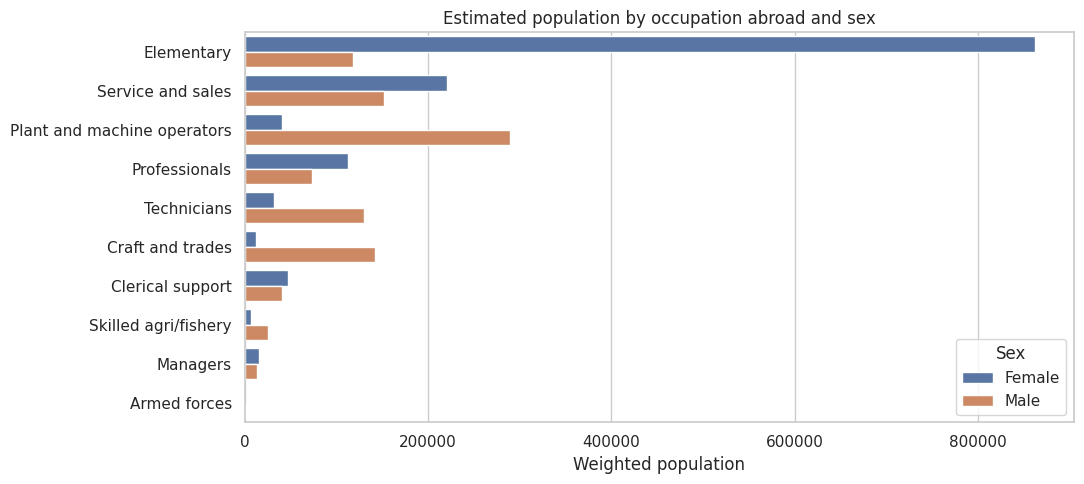

In [ ]:
order = occ_sex.index
plt.figure(figsize=(11,5))
sns.barplot(data=df.dropna(subset=["Occ_abroad"]), y="Occ_abroad", x="RSWGT", hue="Sex", estimator="sum", errorbar=None, order=order)
plt.title("Estimated population by occupation abroad and sex"); plt.xlabel("Weighted population"); plt.ylabel(""); plt.tight_layout(); plt.show()

## 4. Remittance behavior and financial inclusion
Only people with a valid remittance amount are averaged (no zero-filling). Medians are weighted.

In [ ]:
rem = df[df.Remits & df.RQ25_CASHAMT.notna()]
print(f"Remitters in sample: {len(rem)}  |  weighted share of all OFWs who remit: {100*df[df.Remits].RSWGT.sum()/df.RSWGT.sum():.1f}%")
print("Mean remittance among remitters:", round(rem.RQ25_CASHAMT.mean()), "| weighted median:", wmedian(rem.RQ25_CASHAMT, rem.RSWGT))
def remit_table(col, minn=30):
    rows = []
    for k, g in rem.groupby(col, observed=True):
        if len(g) < minn: continue
        rows.append({col:k, "n":len(g), "weighted_pop":g.RSWGT.sum(), "median_remit":wmedian(g.RQ25_CASHAMT, g.RSWGT),
                     "median_income_per_month":wmedian(g.RQ17_AVEMINC, g.RSWGT)})
    return pd.DataFrame(rows).sort_values("median_remit", ascending=False).round(0)
display(remit_table("Occ_abroad")); display(remit_table("Dest"))

Remitters in sample: 2702  |  weighted share of all OFWs who remit: 62.2%
Mean remittance among remitters: 110887 | weighted median: 90000.0


,Occ_abroad,n,weighted_pop,median_remit,median_income_per_month
8,Technicians,181,122916.0,140000.0,80000.0
7,Skilled agri/fishery,32,25299.0,125000.0,65000.0
4,Plant and machine operators,338,252282.0,120000.0,60000.0
5,Professionals,212,154219.0,120000.0,80000.0
1,Craft and trades,181,131745.0,118000.0,50000.0
3,Managers,37,23393.0,105000.0,50000.0
6,Service and sales,405,303915.0,88000.0,35000.0
2,Elementary,1212,802480.0,66000.0,25000.0
0,Clerical support,93,64384.0,60000.0,50000.0


,Dest,n,weighted_pop,median_remit,median_income_per_month
0,Americas,240,194689.0,120000.0,80000.0
1,Australia,88,70264.0,120000.0,60000.0
2,Europe,295,201700.0,120000.0,60000.0
4,Japan,86,55155.0,120000.0,50000.0
7,Other East Asia,80,69241.0,120000.0,60000.0
8,Other SE/S Asia,51,31994.0,90000.0,50000.0
12,Singapore,127,93386.0,90000.0,30000.0
14,UAE,295,219527.0,80000.0,30000.0
5,Kuwait,129,84273.0,78000.0,25000.0
13,Taiwan,112,90074.0,75000.0,45000.0


In [ ]:
mix = rem[rem.Has_mix]
share_cols = {"Consumption":"RQ271P_CONSUM","Investment":"RQ272P_INVEST","Savings":"RQ273P_SAVINGS","Gifts":"RQ274P_GIFT","Other":"RQ275P_OTHERS"}
overall = pd.Series({k: wmean(mix[c], mix.RSWGT) for k, c in share_cols.items()}).round(1)
print("Average spending split of remittances (weighted, %):"); display(overall.to_frame("%"))
by_occ = mix.groupby("Occ_abroad").apply(lambda g: pd.Series({k: wmean(g[c], g.RSWGT) for k, c in share_cols.items()} | {"n":len(g)}), include_groups=False)
display(by_occ[by_occ.n >= 30].sort_values("Savings", ascending=False).round(1))
print("Mode of remittance (weighted %):"); display(wshare(rem, "Mode").to_frame("%"))

Average spending split of remittances (weighted, %):


,%
Consumption,75.4
Investment,5.8
Savings,13.7
Gifts,1.6
Other,3.5


,Consumption,Investment,Savings,Gifts,Other,n
Occ_abroad,,,,,,
Skilled agri/fishery,58.3,10.8,26.9,2.4,1.6,32.0
Technicians,65.4,8.1,21.7,1.7,3.1,178.0
Plant and machine operators,70.8,5.3,20.1,1.3,2.4,333.0
Professionals,72.7,7.1,15.3,3.2,1.8,204.0
Clerical support,76.8,5.1,15.2,1.6,1.3,92.0
Managers,79.5,3.5,14.5,2.2,0.3,36.0
Service and sales,77.6,5.2,11.3,1.9,4.1,400.0
Elementary,77.5,5.7,11.2,1.4,4.2,1176.0
Craft and trades,80.5,5.1,9.5,1.1,3.7,176.0


Mode of remittance (weighted %):


,%
Mode,
Money transfer service,48.8
Bank,47.7
Others,2.6
Agency/local office,0.8
Friends/co-workers,0.1
Door-to-door,0.0


## 5. Remittance-to-income ratio
The period behind `RQ25_CASHAMT` is not stated in the dictionary. Test the candidates before choosing one: a monthly reading would mean most remitters send more than they earn.

In [ ]:
w = df[df.Remits & df.Worked & df.RQ25_CASHAMT.notna() & (df.RQ17_AVEMINC > 0)].copy()
ratio_total = w.RQ25_CASHAMT / w.RQ17_AVEMINC
sens = pd.DataFrame({"Assumed period (months)":[1,3,6,12],
    "Share of remitters sending > 100% of income":[(ratio_total/m > 1).mean()*100 for m in [1,3,6,12]],
    "Weighted median ratio":[wmedian(ratio_total/m, w.RSWGT) for m in [1,3,6,12]]}).round(2)
display(sens)
print("Monthly (1) is not plausible. This notebook uses 6 months (survey reference period April to September 2025). Verify this.")
PERIOD = 6
w["ratio"] = w.RQ25_CASHAMT / (PERIOD * w.RQ17_AVEMINC)

,Assumed period (months),Share of remitters sending > 100% of income,Weighted median ratio
0,1,79.27,2.32
1,3,27.19,0.77
2,6,0.59,0.39
3,12,0.04,0.19


Monthly (1) is not plausible. This notebook uses 6 months (survey reference period April to September 2025). Verify this.


,Occ_abroad,n,median_ratio
2,Elementary,1212,0.44
7,Skilled agri/fishery,32,0.40
6,Service and sales,405,0.36
1,Craft and trades,181,0.36
4,Plant and machine operators,338,0.35
8,Technicians,181,0.33
5,Professionals,212,0.33
3,Managers,37,0.22
0,Clerical support,93,0.20


,Dest,n,median_ratio
5,Kuwait,129,0.50
9,Other W. Asia,101,0.47
12,Singapore,127,0.45
11,Saudi Arabia,692,0.43
6,Malaysia,37,0.42
8,Other SE/S Asia,51,0.40
4,Japan,86,0.40
10,Qatar,150,0.40
7,Other East Asia,78,0.39
14,UAE,295,0.38


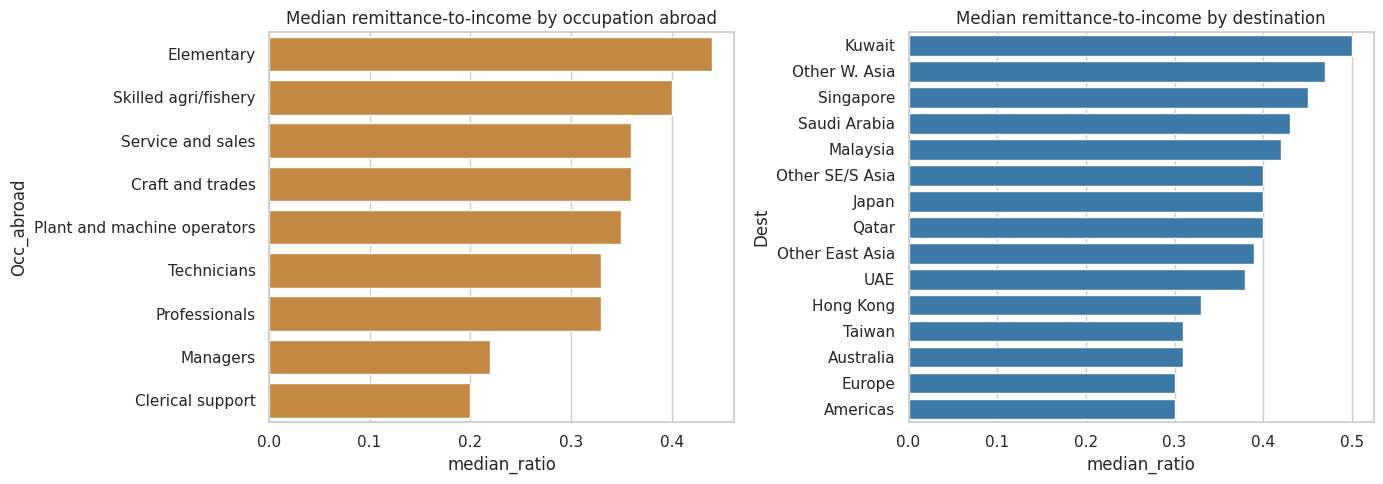

In [ ]:
def ratio_table(col, minn=30):
    rows = [{col:k, "n":len(g), "median_ratio":wmedian(g.ratio, g.RSWGT)} for k, g in w.groupby(col, observed=True) if len(g) >= minn]
    return pd.DataFrame(rows).sort_values("median_ratio", ascending=False).round(2)
r_occ, r_dest = ratio_table("Occ_abroad"), ratio_table("Dest"); display(r_occ); display(r_dest)
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.barplot(data=r_occ, y="Occ_abroad", x="median_ratio", color="#d98a2b", ax=ax[0]); ax[0].set_title("Median remittance-to-income by occupation abroad")
sns.barplot(data=r_dest, y="Dest", x="median_ratio", color="#2b7bb9", ax=ax[1]); ax[1].set_title("Median remittance-to-income by destination")
plt.tight_layout(); plt.show()

## 6. Persona clustering (remitters, valid data, log-scaled)
Zero-filling and skipping the log transform let a handful of extreme values define the clusters. Here the features are income, remittance, months worked, savings and investment shares, and age.

In [ ]:
S = df[df.Remits & df.Worked & df.RQ25_CASHAMT.notna() & df.Has_mix].copy()
X = pd.DataFrame({"log_income":np.log1p(S.RQ17_AVEMINC), "log_remit":np.log1p(S.RQ25_CASHAMT), "months_worked":S.RQ19_NOMONTH,
                  "savings_pct":S.RQ273P_SAVINGS, "invest_pct":S.RQ272P_INVEST, "age":S.RQ4_AGE})
Z = StandardScaler().fit_transform(X)
sil = {k: round(silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z)), 3) for k in range(2, 8)}
print("Silhouette by k:", sil, "(values near 0.2 = modest separation; treat clusters as personas, not hard groups)")
S["Cluster"] = KMeans(4, n_init=20, random_state=42).fit_predict(Z)
prof = S.groupby("Cluster").apply(lambda g: pd.Series({
    "n":len(g), "weighted_pop":g.RSWGT.sum(), "median_income":wmedian(g.RQ17_AVEMINC,g.RSWGT), "median_remit":wmedian(g.RQ25_CASHAMT,g.RSWGT),
    "months_worked":wmean(g.RQ19_NOMONTH,g.RSWGT), "age":wmean(g.RQ4_AGE,g.RSWGT), "consumption_pct":wmean(g.RQ271P_CONSUM,g.RSWGT),
    "savings_pct":wmean(g.RQ273P_SAVINGS,g.RSWGT), "invest_pct":wmean(g.RQ272P_INVEST,g.RSWGT),
    "pct_female":100*g[g.Sex=="Female"].RSWGT.sum()/g.RSWGT.sum(), "top_dest":g.groupby("Dest").RSWGT.sum().idxmax(),
    "top_occ":g.groupby("Occ_abroad").RSWGT.sum().idxmax()}), include_groups=False).round(1)
display(prof)

Silhouette by k: {2: np.float64(0.211), 3: np.float64(0.218), 4: np.float64(0.181), 5: np.float64(0.194), 6: np.float64(0.184), 7: np.float64(0.174)} (values near 0.2 = modest separation; treat clusters as personas, not hard groups)


,n,weighted_pop,median_income,median_remit,months_worked,age,consumption_pct,savings_pct,invest_pct,pct_female,top_dest,top_occ
Cluster,,,,,,,,,,,,
0,569,405366.6,90000.0,200000.0,27.3,41.3,63.0,27.2,6.2,24.7,Americas,Plant and machine operators
1,1034,741274.7,30000.0,60000.0,16.0,33.8,80.2,12.6,1.8,67.3,Saudi Arabia,Elementary
2,221,127661.2,30000.0,90000.0,22.4,36.9,42.0,9.8,45.9,66.9,Saudi Arabia,Elementary
3,804,558615.7,30000.0,78000.0,40.1,43.2,85.7,6.4,1.7,66.4,Saudi Arabia,Elementary


Suggested names ONLY if your run matches the profiles above (cluster numbers can change); check the table first: {0: 'High earners who save', 1: 'Newer mid-income senders', 2: 'Investor-minded', 3: 'Long-stay, spend-first'}


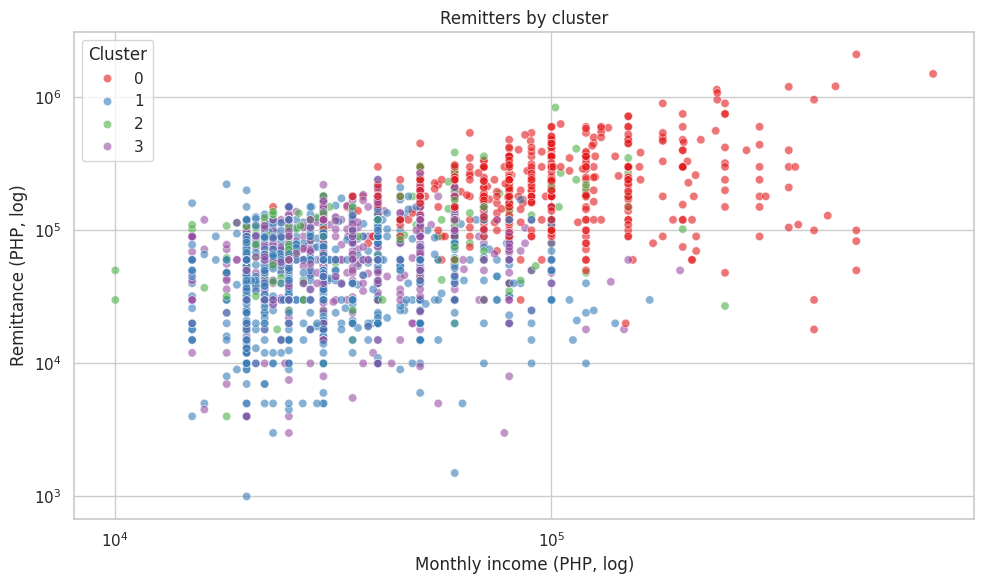

In [ ]:
names = {0:"High earners who save",1:"Newer mid-income senders",2:"Investor-minded",3:"Long-stay, spend-first"}
print("Suggested names ONLY if your run matches the profiles above (cluster numbers can change); check the table first:", names)
plt.figure(figsize=(10,6)); sns.scatterplot(data=S, x="RQ17_AVEMINC", y="RQ25_CASHAMT", hue="Cluster", palette="Set1", alpha=.6)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Monthly income (PHP, log)"); plt.ylabel("Remittance (PHP, log)")
plt.title("Remitters by cluster"); plt.tight_layout(); plt.show()

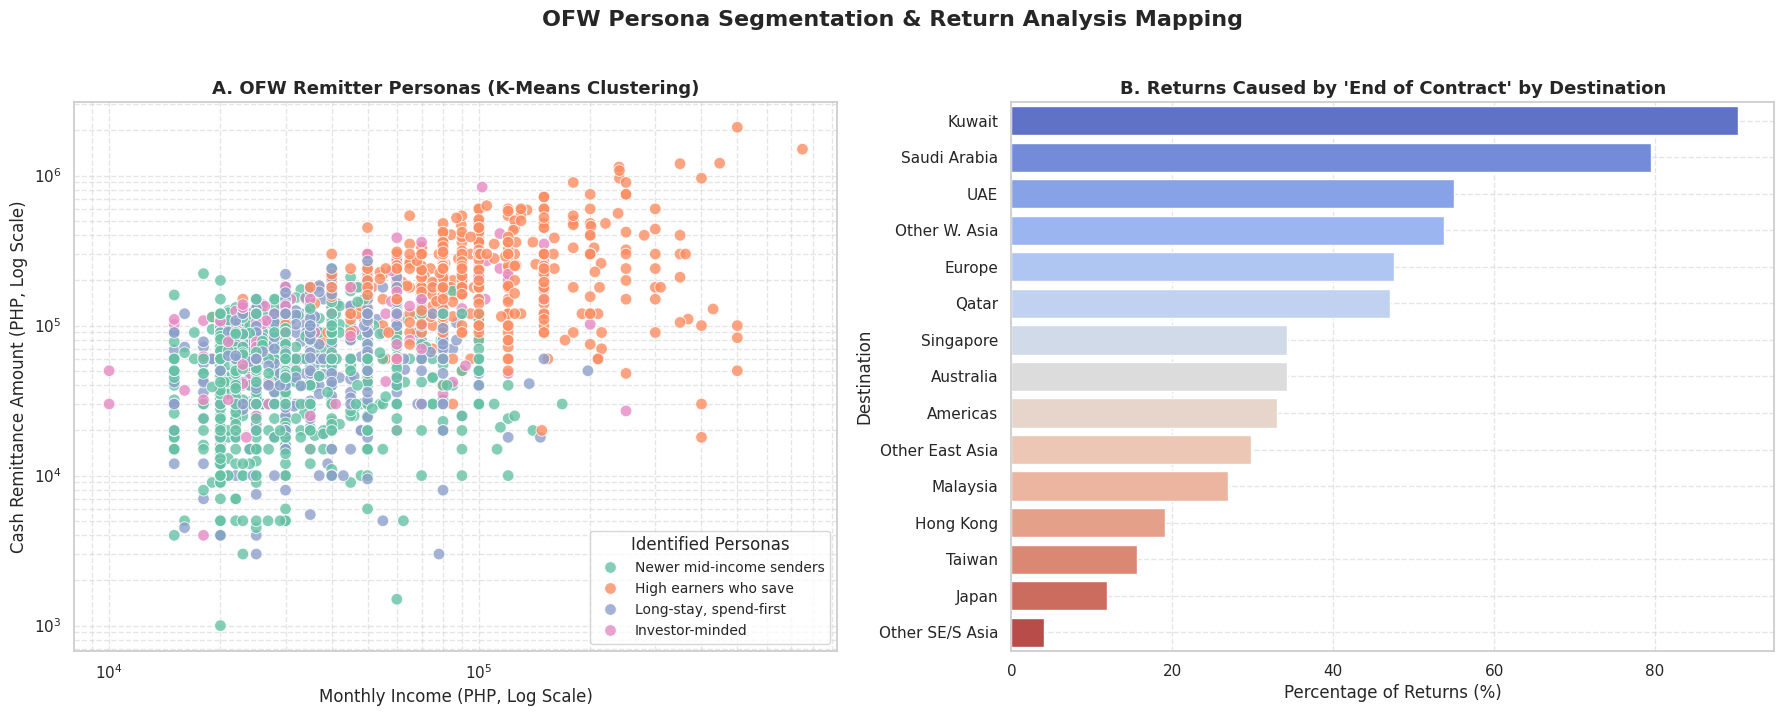

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map cluster IDs to their official Persona names if not already mapped
S['Persona'] = S['Cluster'].map(names)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Panel 1: Persona Scatter Plot
sns.scatterplot(
    data=S,
    x="RQ17_AVEMINC",
    y="RQ25_CASHAMT",
    hue="Persona",
    palette="Set2",
    alpha=0.8,
    edgecolor='w',
    s=70,
    ax=axes[0]
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Monthly Income (PHP, Log Scale)", fontsize=12)
axes[0].set_ylabel("Cash Remittance Amount (PHP, Log Scale)", fontsize=12)
axes[0].set_title("A. OFW Remitter Personas (K-Means Clustering)", fontsize=13, fontweight='bold')
axes[0].legend(title="Identified Personas", loc='lower right', fontsize=10)
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Panel 2: Return Patterns driven by End of Contract
top_dests = end[end.n >= 30].sort_values("% end of contract", ascending=False)
sns.barplot(
    data=top_dests,
    x="% end of contract",
    y=top_dests.index,
    palette="coolwarm",
    hue=top_dests.index,
    legend=False,
    ax=axes[1]
)
axes[1].set_xlabel("Percentage of Returns (%)", fontsize=12)
axes[1].set_ylabel("Destination", fontsize=12)
axes[1].set_title("B. Returns Caused by 'End of Contract' by Destination", fontsize=13, fontweight='bold')
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.suptitle("OFW Persona Segmentation & Return Analysis Mapping", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

/tmp/ipykernel_526/1887950688.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pers_pct.values, y=pers_pct.index, palette="magma")


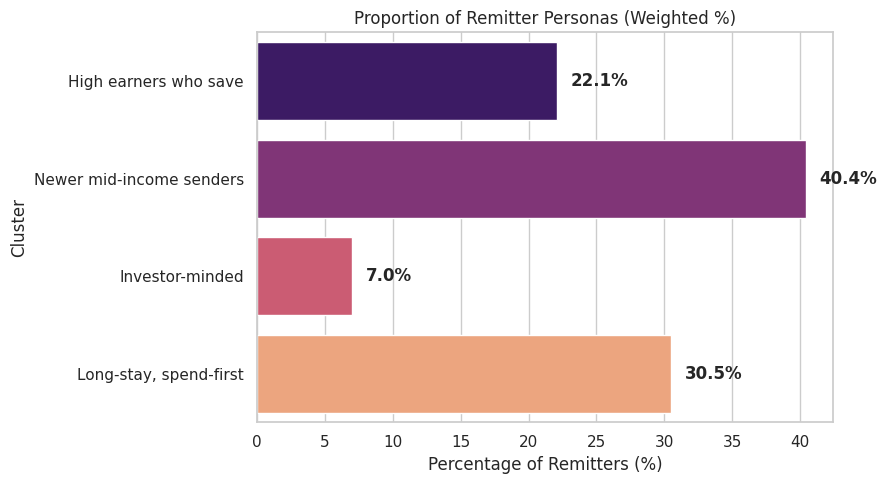

In [ ]:
pers_pop = S.groupby('Cluster').RSWGT.sum()
pers_pct = (pers_pop / pers_pop.sum() * 100).round(1)
pers_pct.index = pers_pct.index.map(names)

plt.figure(figsize=(9, 5))
sns.barplot(x=pers_pct.values, y=pers_pct.index, palette="magma")
plt.title("Proportion of Remitter Personas (Weighted %)")
plt.xlabel("Percentage of Remitters (%)")
for i, v in enumerate(pers_pct.values):
    plt.text(v + 1, i, f"{v}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Return and reintegration
`RQ20_RET` = has returned home. `RQ22_REASON` = reason for returning. `RQ28_RET6MOS` = returned during April to September 2025 (a past event, not an intention).

Returned home: 1581 records, 38.4% of the weighted population
Reasons for returning (weighted %):


,%
Ret_reason,
Others,56.4
End of contract,35.9
Visit friends/relatives,7.4
COVID-19 repatriation,0.3


Returned during April to September 2025 (RQ28), weighted %: 20.1


,% returned
Tenure,
<1y,16.7
1-2y,18.1
2-3y,30.6
3-4y,23.5
4-5y,20.2


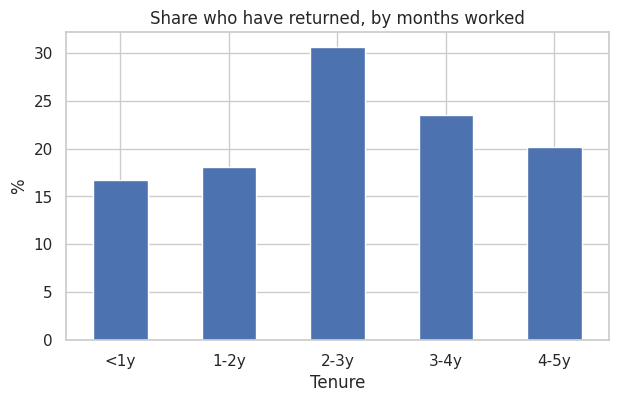

,n,% end of contract
Dest,,
Kuwait,51.0,90.3
Saudi Arabia,198.0,79.5
UAE,87.0,55.0
Other W. Asia,43.0,53.8
Europe,146.0,47.6
Qatar,45.0,47.1
Singapore,116.0,34.3
Australia,66.0,34.2
Americas,175.0,33.0


Note: 'Others' is the largest stated reason, so conclusions about why people return are limited.


In [ ]:
ret = df[df.Returned]
print(f"Returned home: {len(ret)} records, {100*ret.RSWGT.sum()/df.RSWGT.sum():.1f}% of the weighted population")
print("Reasons for returning (weighted %):"); display(wshare(ret, "Ret_reason").to_frame("%"))
print("Returned during April to September 2025 (RQ28), weighted %:", round(100*df[df.RQ28_RET6MOS == 1].RSWGT.sum()/df.RSWGT.sum(), 1))
ten = df[df.Worked].copy(); ten["Tenure"] = pd.cut(ten.RQ19_NOMONTH, [-1,11,23,35,47,60], labels=["<1y","1-2y","2-3y","3-4y","4-5y"])
share_ret = ten.groupby("Tenure", observed=True).apply(lambda g: 100*g[g.Returned].RSWGT.sum()/g.RSWGT.sum(), include_groups=False).round(1)
display(share_ret.to_frame("% returned")); share_ret.plot.bar(rot=0, figsize=(7,4), title="Share who have returned, by months worked"); plt.ylabel("%"); plt.show()
end = ret.groupby("Dest").apply(lambda g: pd.Series({"n":len(g), "% end of contract":100*g[g.Ret_reason=="End of contract"].RSWGT.sum()/g.RSWGT.sum()}), include_groups=False)
display(end[end.n >= 30].sort_values("% end of contract", ascending=False).round(1))
print("Note: 'Others' is the largest stated reason, so conclusions about why people return are limited.")

## 8. Regional supply and demographic pipeline

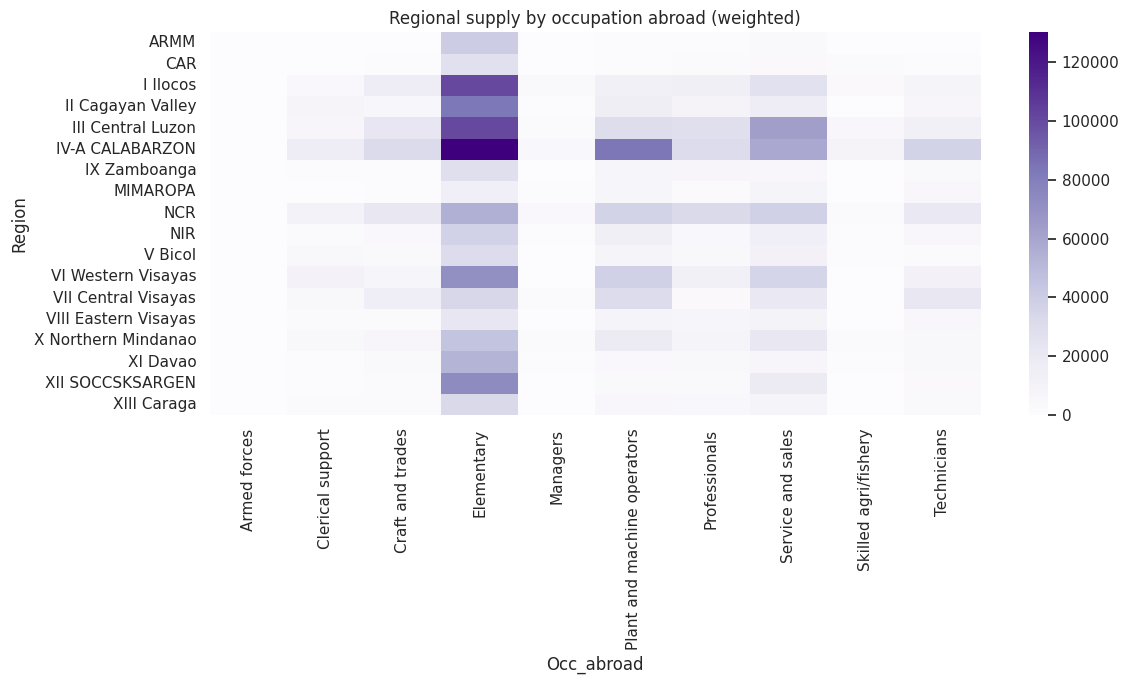

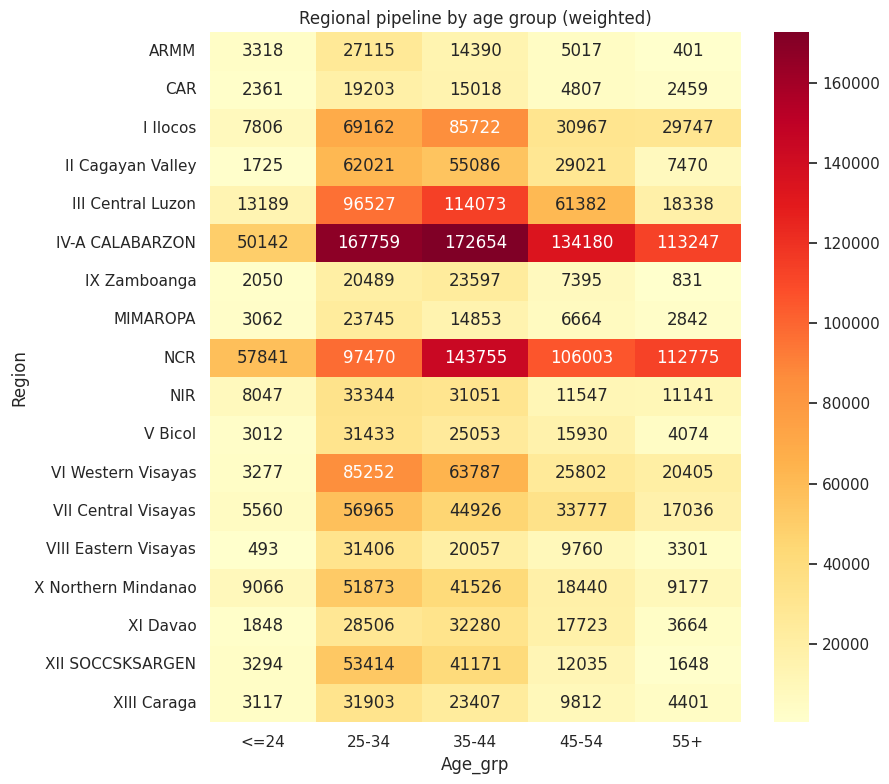

In [ ]:
rs = df.groupby(["Region","Occ_abroad"]).RSWGT.sum().unstack().fillna(0)
plt.figure(figsize=(12,7)); sns.heatmap(rs, cmap="Purples"); plt.title("Regional supply by occupation abroad (weighted)"); plt.tight_layout(); plt.show()
ra = pd.crosstab(df.Region, df.Age_grp, values=df.RSWGT, aggfunc="sum").fillna(0).round(0).astype(int)
plt.figure(figsize=(9,8)); sns.heatmap(ra, annot=True, fmt="d", cmap="YlOrRd"); plt.title("Regional pipeline by age group (weighted)"); plt.tight_layout(); plt.show()

## 9. Sea-based vs land-based

In [ ]:
sl = df[df.Worked].groupby("Base", observed=True).apply(lambda g: pd.Series({
    "n":len(g), "weighted_pop":g.RSWGT.sum(), "pct_remit":100*g[g.Remits].RSWGT.sum()/g.RSWGT.sum(),
    "median_income":wmedian(g.RQ17_AVEMINC,g.RSWGT), "median_remit":wmedian(g.RQ25_CASHAMT,g.RSWGT)}), include_groups=False).round(1)
display(sl)

,n,weighted_pop,pct_remit,median_income,median_remit
Base,,,,,
Land-based,2751.0,1920991.6,81.4,30000.0,80000.0
Other,3.0,1971.1,77.8,120000.0,144000.0
Sea-based,596.0,402035.9,77.2,75000.0,125000.0


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
import numpy as np

# Prepare dataset for propensity modeling (predicting 'Remits')
# Exclude non-workers as they almost never remit
model_df = df[df.Worked].copy()

features = ['Sex', 'Marital', 'Education', 'Region', 'Age_grp']
target = 'Remits'

# Drop rows where target is missing
model_df = model_df.dropna(subset=[target]).reset_index(drop=True)

X_model = model_df[features].astype(str)
y_model = model_df[target].astype(int)
weights = model_df['RSWGT'].values

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), features)
    ]
)

# 5-fold cross-validation manually to apply sample weights properly on train fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for train_idx, val_idx in cv.split(X_model, y_model):
    X_train, y_train = X_model.iloc[train_idx], y_model.iloc[train_idx]
    X_val, y_val = X_model.iloc[val_idx], y_model.iloc[val_idx]
    w_train, w_val = weights[train_idx], weights[val_idx]

    # Clone and build pipeline
    pipeline = make_pipeline(preprocessor, LogisticRegression(max_iter=1000, random_state=42))

    # Fit with sample weights
    pipeline.fit(X_train, y_train, logisticregression__sample_weight=w_train)

    # Predict probabilities
    y_pred_proba = pipeline.predict_proba(X_val)[:, 1]

    # Calculate weighted ROC AUC
    auc = roc_auc_score(y_val, y_pred_proba, sample_weight=w_val)
    scores.append(auc)

scores = np.array(scores)
print(f"5-Fold CV AUC Scores: {scores}")
print(f"Mean AUC: {scores.mean():.2f} (Standard Deviation: {scores.std():.2f})")

5-Fold CV AUC Scores: [0.57984506 0.61330551 0.51601025 0.59304865 0.54012966]
Mean AUC: 0.57 (Standard Deviation: 0.04)


### 11. Remittance Allocation and Channels

/tmp/ipykernel_526/888863497.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=overall.values, y=overall.index, palette="viridis")


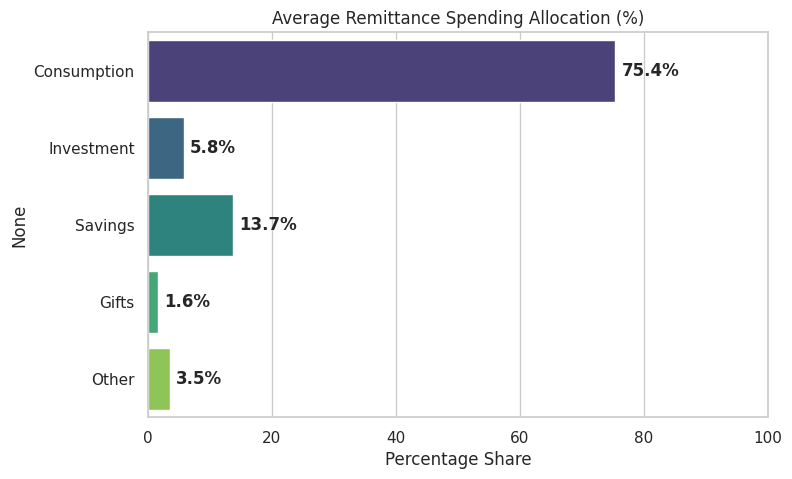

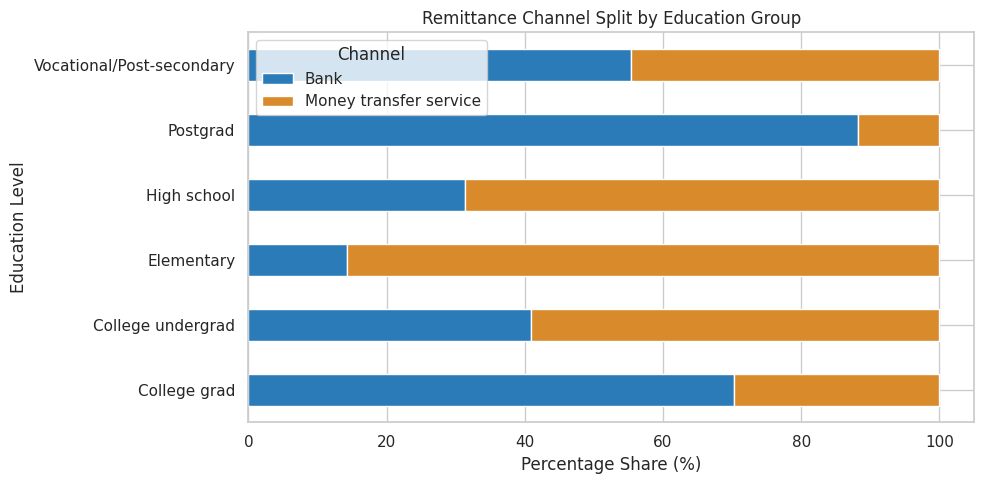

In [ ]:
# 1. Spending allocation chart
plt.figure(figsize=(8, 5))
sns.barplot(x=overall.values, y=overall.index, palette="viridis")
plt.title("Average Remittance Spending Allocation (%)")
plt.xlabel("Percentage Share")
plt.xlim(0, 100)
for i, v in enumerate(overall.values):
    plt.text(v + 1, i, f"{v}%", va='center', fontweight='bold')
plt.show()

# 2. Payment Channel Split by Education level
channel_df = df[df.Remits & df.Mode.isin(['Bank', 'Money transfer service'])].copy()
channel_cross = pd.crosstab(channel_df.Education, channel_df.Mode, values=channel_df.RSWGT, aggfunc='sum', normalize='index') * 100

channel_cross.plot(kind='barh', stacked=True, figsize=(10, 5), color=['#2b7bb9', '#d98a2b'])
plt.title("Remittance Channel Split by Education Group")
plt.xlabel("Percentage Share (%)")
plt.ylabel("Education Level")
plt.legend(title="Channel")
plt.tight_layout()
plt.show()